In [88]:
import pandas as pd
import numpy  as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

In [89]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import PowerTransformer

In [90]:
url = (
    "https://raw.githubusercontent.com/campusx-official/"
    "100-days-of-machine-learning/main/day31-power-transformer/concrete_data.csv"
)
df = pd.read_csv(url)

In [91]:
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


> ## Power transformer
> Power transforms are a family of parametric, monotonic transformations that are applied to make data more Gaussian-like. This is useful for modeling issues related to heteroscedasticity (non-constant variance), or other situations where normality is desired.

>Currently, power_transform supports the Box-Cox transform and the Yeo-Johnson transform. The optimal parameter for stabilizing variance and minimizing skewness is estimated through maximum likelihood.

>Box-Cox requires input data to be strictly positive, while Yeo-Johnson supports both positive or negative data.

>By default, zero-mean, unit-variance normalization is applied to the transformed data.
> https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.power_transform.html

In [92]:
df.shape

(1030, 9)

In [93]:
df.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [94]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [95]:
X= df.drop(columns=['Strength'])
y = df.iloc[:,-1]


In [96]:
X_train,X_test,y_train,y_test =train_test_split(X,y,test_size=0.2,random_state=42)

In [97]:
lr = LinearRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
r2_score(y_test,y_pred)

0.6275531792314851

In [98]:
lr  = LinearRegression()
np.mean(cross_val_score(lr,X,y,scoring='r2'))

np.float64(0.4609940491662865)

> ## box cox

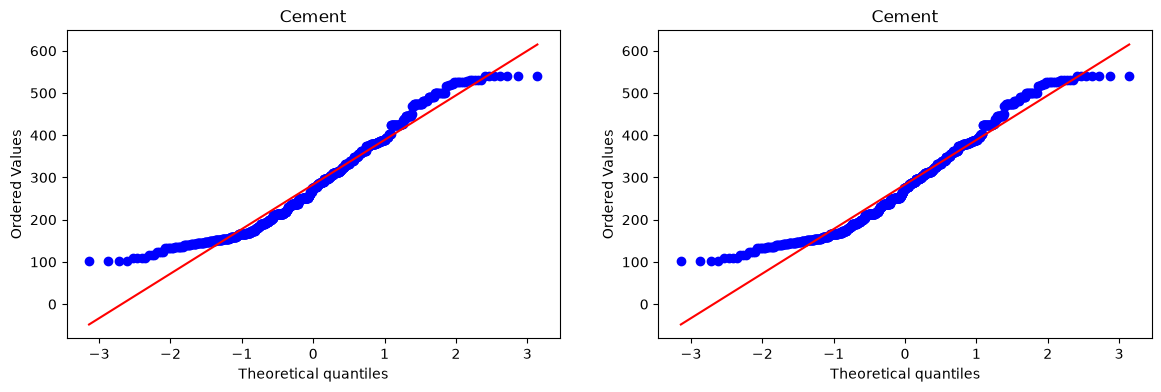

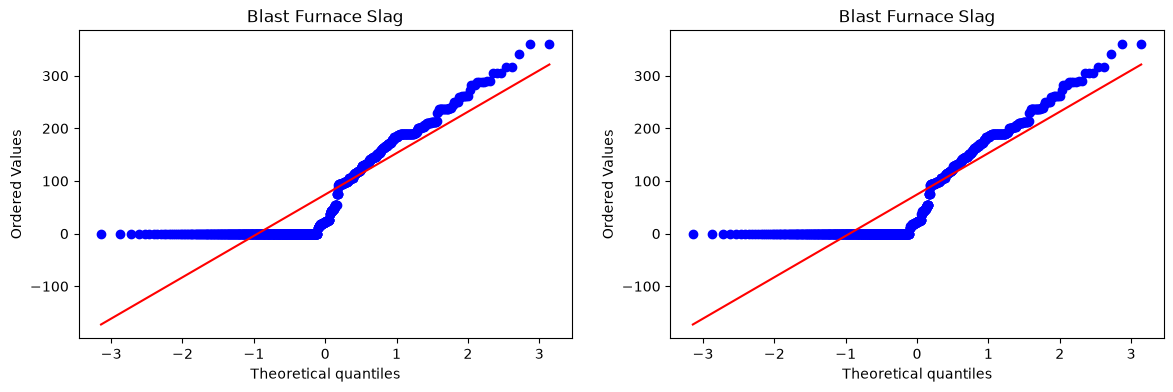

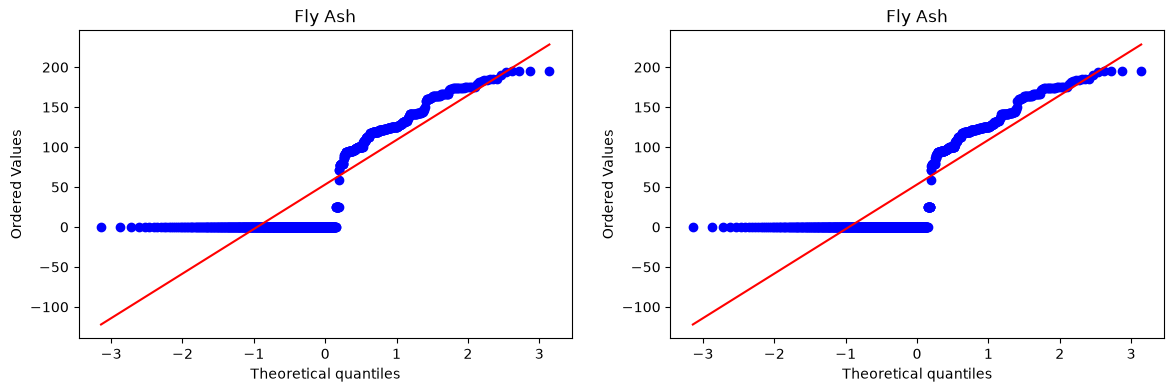

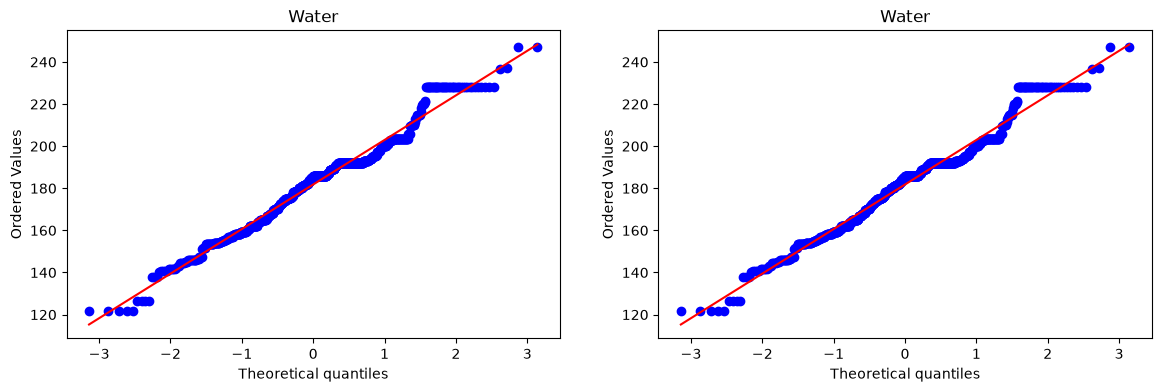

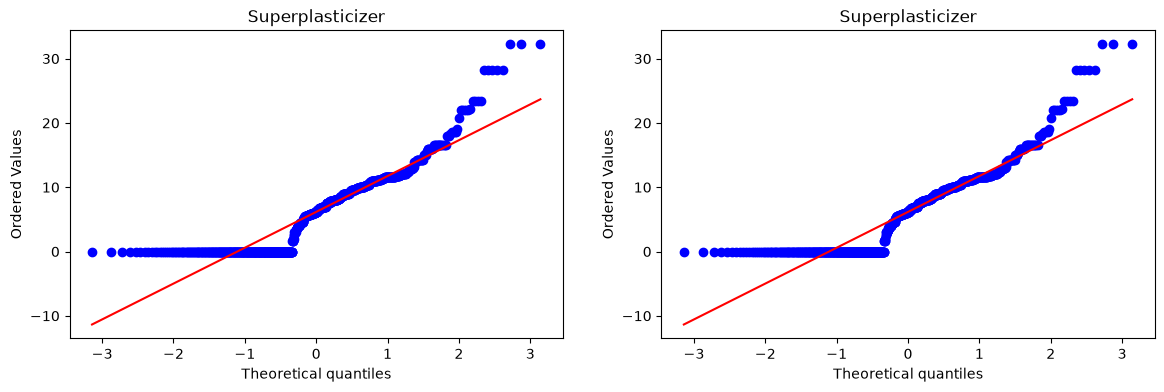

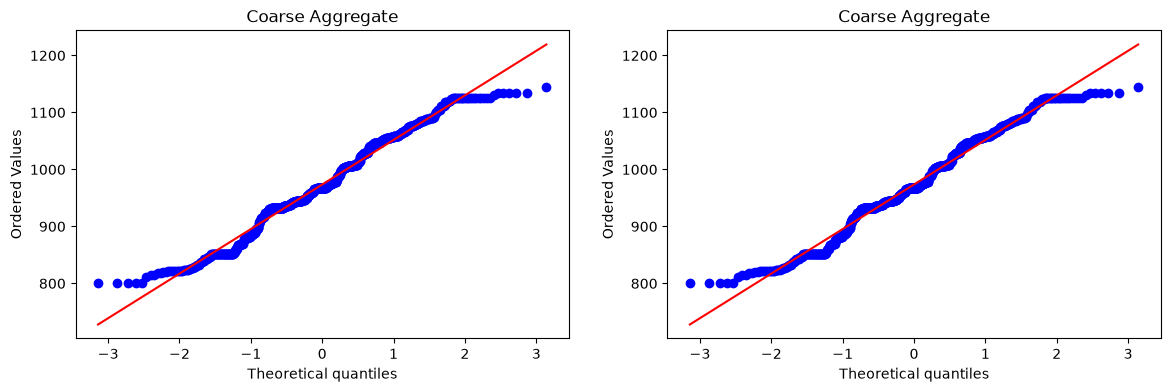

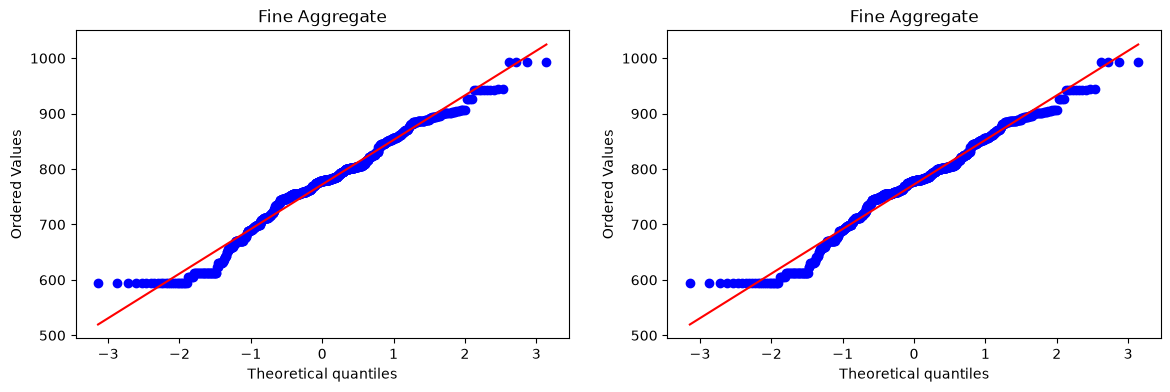

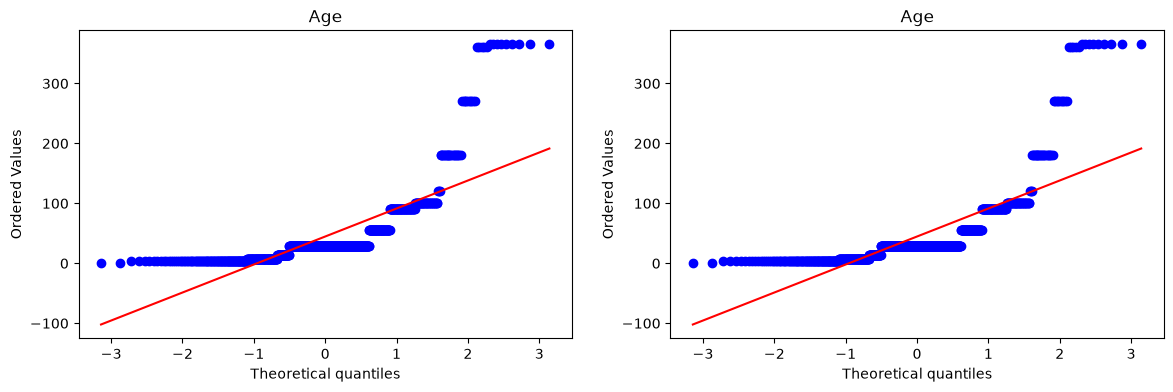

In [99]:
# apply box cox
for col in X_train.columns:
    plt.figure(figsize=(14, 4))
    

    plt.subplot(121)
    stats.probplot(X_train[col], dist="norm", plot=plt)
    plt.title(col)

    plt.subplot(122)
    stats.probplot(X_train[col], dist="norm", plot=plt)
    plt.title(col)

    plt.show()
    

In [100]:
pt = PowerTransformer(method='box-cox')
X_train_transformed = pt.fit_transform(X_train+0.00001)
X_test_transformed = pt.fit_transform(X_test+0.00001)
pd.DataFrame({'cols':X_train.columns,'box_cox_lambdas':pt.lambdas_})

,cols,box_cox_lambdas
0,Cement,0.215602
1,Blast Furnace Slag,0.028899
2,Fly Ash,-0.007561
3,Water,0.959062
4,Superplasticizer,0.119398
5,Coarse Aggregate,1.192491
6,Fine Aggregate,1.973781
7,Age,-0.014692


In [101]:
lr = LinearRegression()
lr.fit(X_train_transformed,y_train)
y_pred2 = lr.predict(X_test_transformed)
r2_score(y_test,y_pred2)

0.8061415974444239

In [102]:
pt = PowerTransformer(method='box-cox')
X_transformed = pt.fit_transform(X +0.00001)
lr = LinearRegression()
np.mean(cross_val_score(lr,X_transformed,y,scoring='r2'))

np.float64(0.6668489649183532)

> ## yeo-johnson

In [103]:
# apply box cox transformed
pt = PowerTransformer()
X_train_transformed2 = pt.fit_transform(X_train)
X_test_transformed2 = pt.fit_transform(X_test)

lr = LinearRegression()
lr.fit(X_train_transformed,y_train)
y_pred3 = lr.predict(X_test_transformed2)
print(r2_score(y_test,y_pred3))

pd.DataFrame({'cols':X_train.columns,'yeo_johnson_lambdas':pt.lambdas_})

0.8010744294008686


,cols,yeo_johnson_lambdas
0,Cement,0.213025
1,Blast Furnace Slag,0.020476
2,Fly Ash,-0.038218
3,Water,0.958936
4,Superplasticizer,0.304951
5,Coarse Aggregate,1.192751
6,Fine Aggregate,1.975085
7,Age,-0.062443


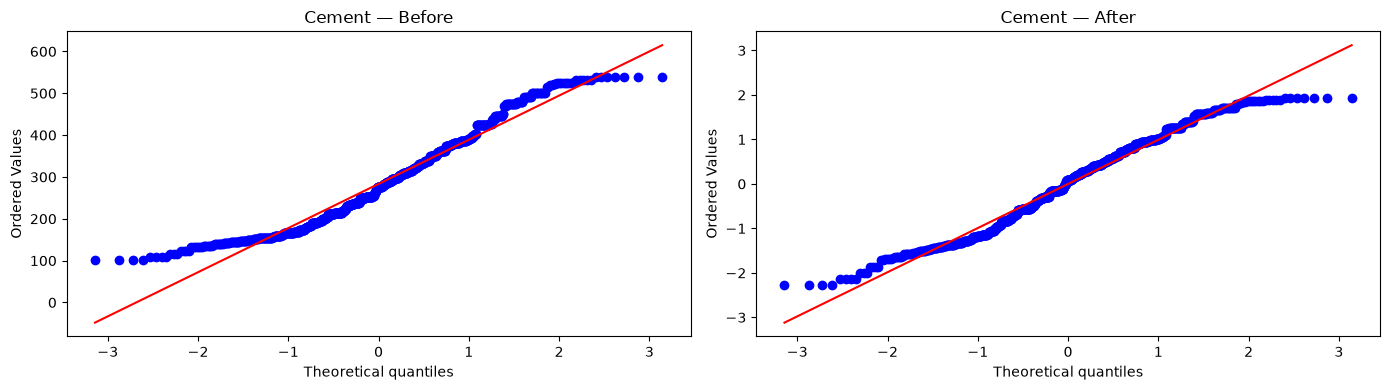

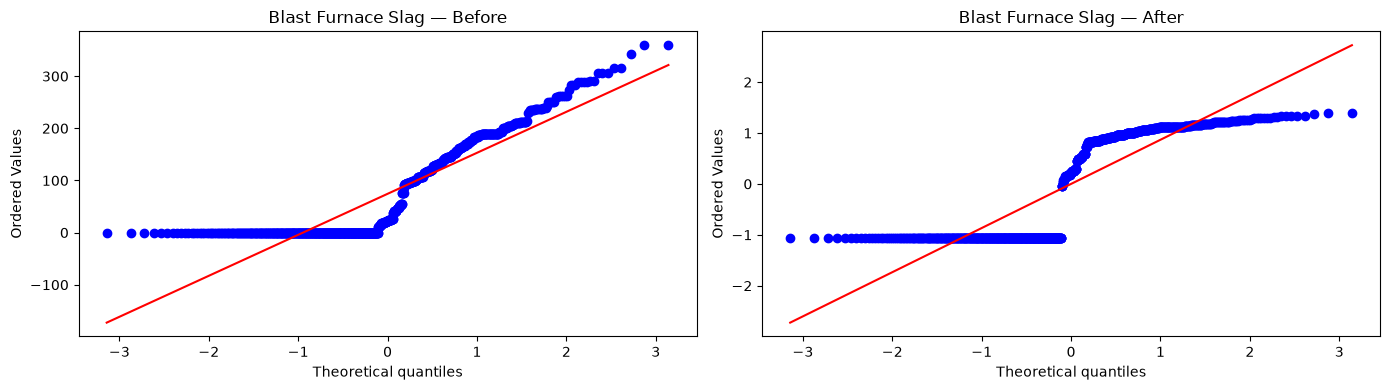

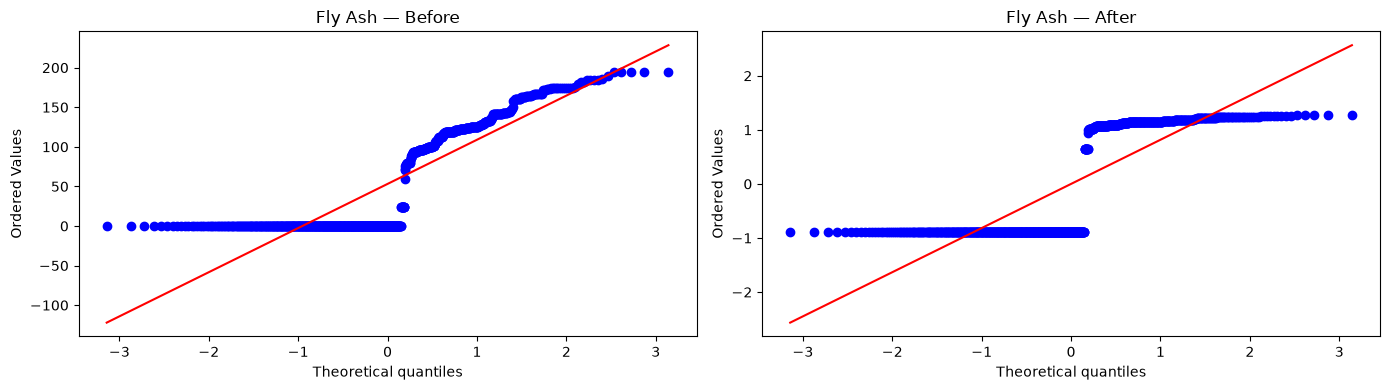

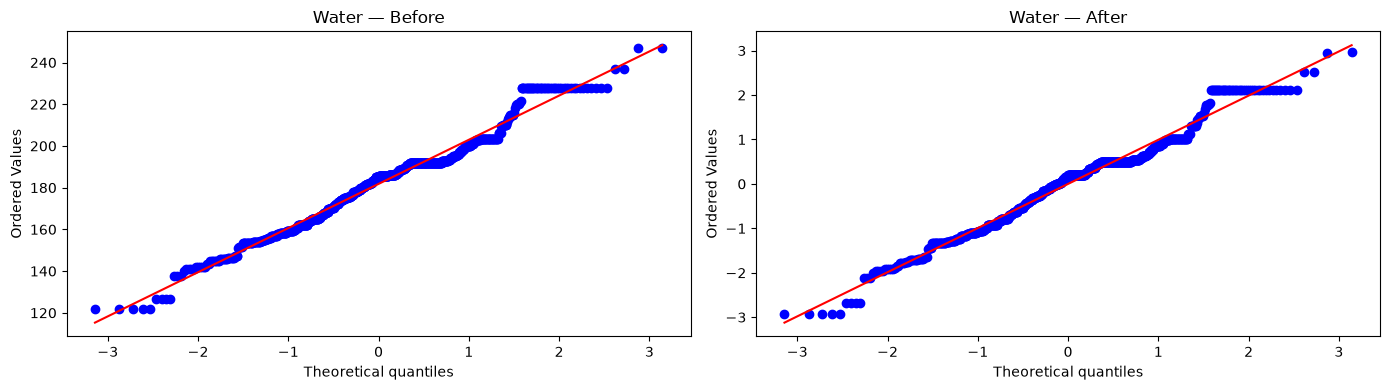

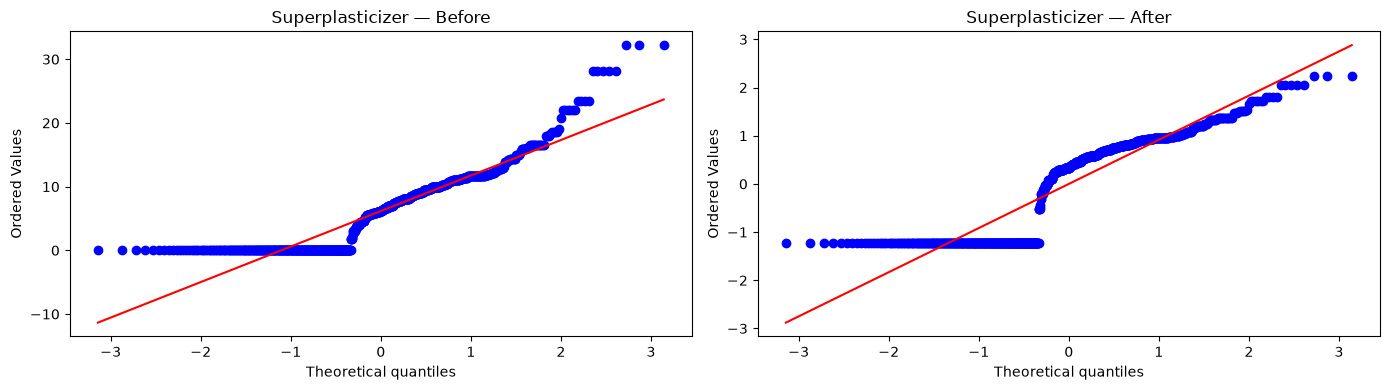

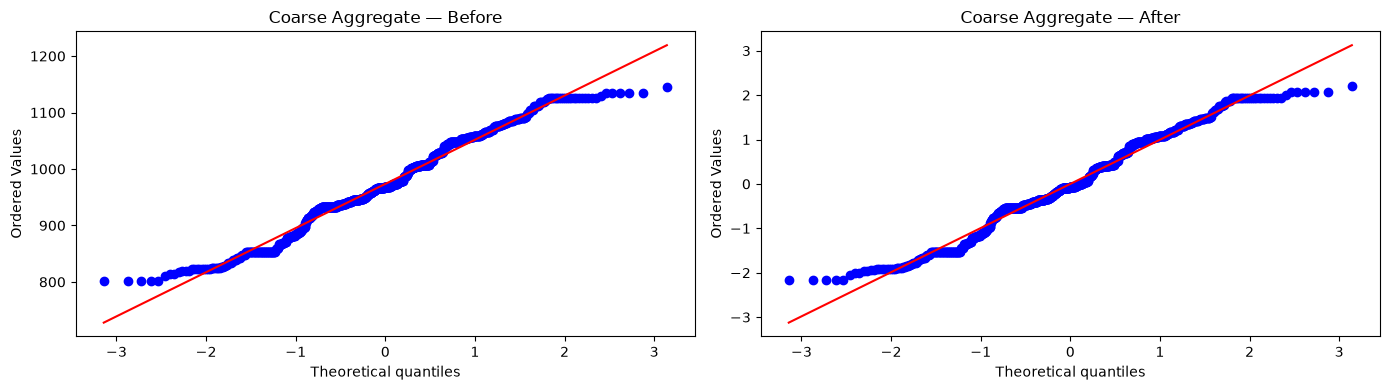

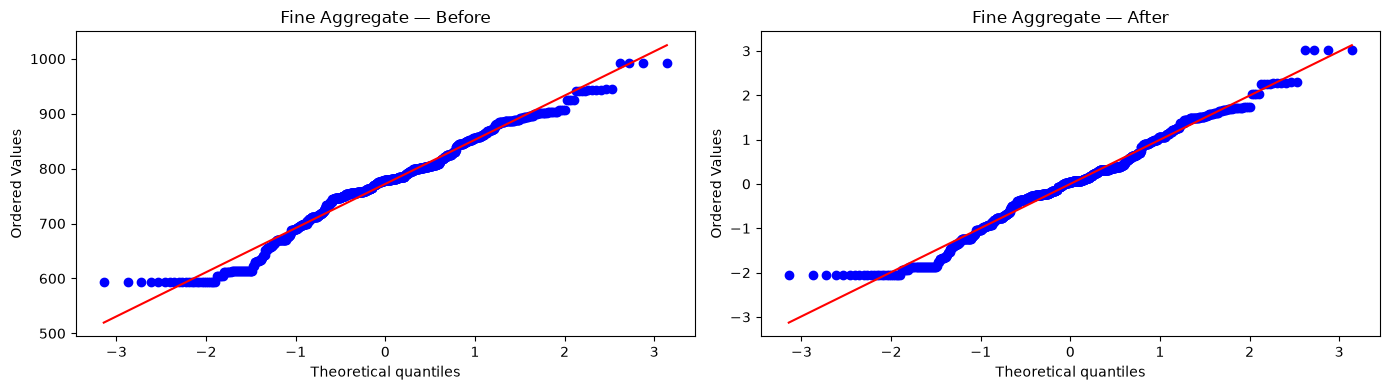

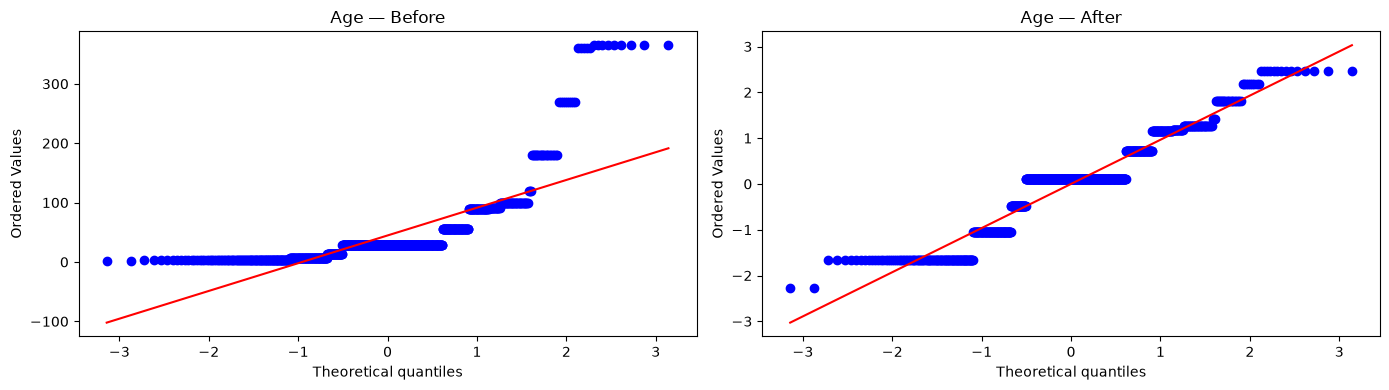

In [110]:
X_train_transformed2 = pd.DataFrame(
    X_train_transformed2, columns=X_train.columns
)

for col in X_train.columns:
  plt.figure(figsize=(14, 4))

  plt.subplot(121)
  stats.probplot(X_train[col], dist="norm", plot=plt)
  plt.title(f"{col} — Before")

  plt.subplot(122)
  stats.probplot(X_train_transformed2[col], dist="norm", plot=plt)
  plt.title(f"{col} — After")

  plt.tight_layout()
  plt.show()